# Value-Based Customer Churn Prediction & Prioritized Retention List
**Joseph Ikogho · Data Science Portfolio Project 1**

Business goal: find potential churners, prioritize probability-weighted monthly revenue exposure, and set retention spending limits. Public IBM Telco sample. Dollar amounts are scenarios, not achieved savings. Designed by Nova Agentic.

## 1. Framework and data
The model supports a decision, not a model leaderboard. We use a prior baseline and one logistic regression. Three separate decisions are retained: a recall-first risk flag, an exact p × monthly value rank, and a cost/capacity-constrained campaign. IBM supplies cross-sectional sample labels, not timestamped forward churn outcomes; a live deployment needs prospective validation.

In [1]:
from pathlib import Path
import os,sys,json
ROOT=Path.cwd() if (Path.cwd()/'src/train.py').exists() else Path.cwd().parent
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Image
from src.train import load_data,main
from src.business import prioritize,campaign
d=load_data()
print('Rows / columns:',d.shape)
print('Unique IDs:',d.customerID.nunique())
print('Churn prevalence:',d.Churn.eq('Yes').mean())
d.head()

Rows / columns: (7043, 21)
Unique IDs: 7043
Churn prevalence: 0.2653698707936959
Out[1]: 
   customerID  gender  SeniorCitizen  ... MonthlyCharges TotalCharges  Churn
0  7590-VHVEG  Female              0  ...          29.85        29.85     No
1  5575-GNVDE    Male              0  ...          56.95      1889.50     No
2  3668-QPYBK    Male              0  ...          53.85       108.15    Yes
3  7795-CFOCW    Male              0  ...          42.30      1840.75     No
4  9237-HQITU  Female              0  ...          70.70       151.65    Yes

[5 rows x 21 columns]


## 2. Training-only exploration and quality
Eleven blank cumulative charges become missing values and are imputed inside fitting folds. Explore the training partition only; do not use test plots to redesign the model. Customer ID, target and demographics are excluded from predictors. Associations do not establish causes.

,missing
TotalCharges,11


,tenure,MonthlyCharges,TotalCharges
count,4225.000000,4225.000000,4218.000000
mean,32.442840,64.894509,2299.298898
std,24.629184,30.326002,2287.781722
min,0.000000,18.400000,18.850000
25%,9.000000,35.400000,402.525000
50%,29.000000,70.550000,1373.625000
75%,55.000000,90.100000,3865.562500
max,72.000000,118.750000,8684.800000


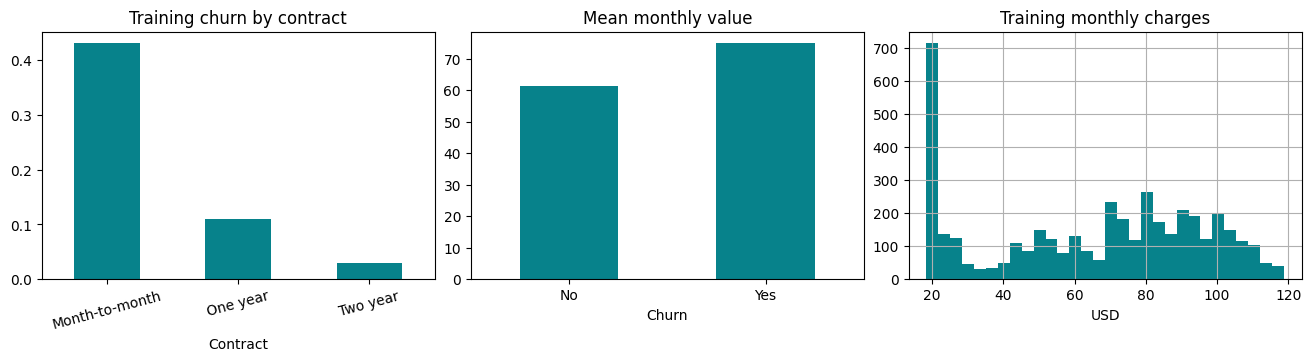

In [2]:
from sklearn.model_selection import train_test_split
y=d.Churn.eq('Yes').astype(int)
tr,_=train_test_split(d.index,test_size=.4,stratify=y,random_state=42)
fit=d.loc[tr]
display(d.isna().sum().to_frame('missing').query('missing > 0'))
display(fit[['tenure','MonthlyCharges','TotalCharges']].describe())
fig,ax=plt.subplots(1,3,figsize=(13,3.5),layout='constrained')
fit.groupby('Contract').Churn.apply(lambda x:x.eq('Yes').mean()).plot.bar(ax=ax[0],rot=15,color='#07828b',title='Training churn by contract')
fit.groupby('Churn').MonthlyCharges.mean().plot.bar(ax=ax[1],rot=0,color='#07828b',title='Mean monthly value')
fit.MonthlyCharges.hist(bins=30,ax=ax[2],color='#07828b');ax[2].set(title='Training monthly charges',xlabel='USD')
plt.show()

## 3. Fit a simple model and select a recall-first screen
Stratified 60/20/20 split; seed 42. Preprocessing occurs inside five training-only sigmoid-calibration folds. Logistic regression is the chosen simple algorithm; the prior classifier checks baseline probability quality. The flag threshold is the highest validation threshold attaining at least 85% recall. Taking the highest qualifying threshold limits false positives; maximizing recall without a constraint would flag everyone. Precision is secondary and reported openly.

In [3]:
main()
m=json.loads(Path('outputs/metrics.json').read_text())
display(pd.read_csv('outputs/validation_metrics.csv'))
print('Validation recall:',m['validation_recall'],'threshold:',m['threshold'])
display(pd.DataFrame([{'policy':'Recall-first','recall':m['recall'],'precision':m['precision'],'threshold':m['threshold']},{'policy':'Default 0.50','recall':m['test_at_threshold_0_5']['recall'],'precision':m['test_at_threshold_0_5']['precision'],'threshold':.5}]))
print('Test matrix [actual stay/churn rows, predicted stay/churn columns]:',m['confusion_matrix'])

{
  "roc_auc": 0.8326642382908367,
  "pr_auc": 0.6252198859296575,
  "brier": 0.14127545556740828,
  "precision": 0.484375,
  "recall": 0.8288770053475936,
  "f1": 0.611439842209073,
  "f2": 0.7256554307116105,
  "auc_ci95": [
    0.8102076994204527,
    0.8541469792764329
  ],
  "winner": "logistic",
  "threshold": 0.24,
  "rows": 7043,
  "test_rows": 1409,
  "churn_rate": 0.2653698707936959,
  "test_churn_rate": 0.2654364797728886,
  "missing_total_charges": 11,
  "monthly_revenue_at_risk": 28314.460007663263,
  "six_month_revenue_at_risk": 169886.7600459796,
  "campaign": {
    "strategy": "value",
    "contacts": 200,
    "expected_saved_revenue": 17781.175194072537,
    "expected_net_value": 8446.822635850775,
    "label_based_scenario_net": 8496.994999999999
  },
  "confusion_matrix": [
    [
      705,
      330
    ],
    [
      64,
      310
    ]
  ],
  "flagged_customers": 640,
  "validation_recall": 0.8529411764705882,
  "test_at_threshold_0_5": {
    "roc_auc": 0.83266423

,model,roc_auc,pr_auc,brier,precision,recall,f1,f2
0,baseline,0.50000,0.265436,0.194980,0.000000,0.000000,0.000000,0.00000
1,logistic,0.86012,0.678126,0.130489,0.679128,0.582888,0.627338,0.59989


,policy,recall,precision,threshold
0,Recall-first,0.828877,0.484375,0.24
1,Default 0.50,0.534759,0.621118,0.50


## 4. Weigh false positives and false negatives
FP = contact a customer who stays; FN = miss a churner. Set illustrative penalties FP=$20 and FN=$100 (5:1), then vary the ratio. These are diagnostic assumptions, separate from ROI—not measured company costs. Cost-minimizing comparison thresholds are chosen on validation only; they are not used to retune the final recall rule on test results.

,threshold,recall,precision,fp,fn,diagnostic_cost_5_to_1
15,0.15,0.941176,0.427184,472,22,11640
16,0.16,0.935829,0.435323,454,24,11480
17,0.17,0.930481,0.445013,434,26,11280
18,0.18,0.922460,0.453947,415,29,11200
19,0.19,0.911765,0.463315,395,33,11200
20,0.20,0.887701,0.470922,373,42,11660
21,0.21,0.877005,0.473988,364,46,11880
22,0.22,0.863636,0.477105,354,51,12180
23,0.23,0.852941,0.481146,344,55,12380
24,0.24,0.852941,0.491525,330,55,12100


,fn_to_fp_ratio,policy,threshold,fp,fn,diagnostic_cost
0,1,recall_first,0.24,330,64,7880
1,1,default_0_5,0.50,122,174,5920
2,1,validation_cost_min,0.56,92,208,6000
3,3,recall_first,0.24,330,64,10440
4,3,default_0_5,0.50,122,174,12880
5,3,validation_cost_min,0.32,245,90,10300
6,5,recall_first,0.24,330,64,13000
7,5,default_0_5,0.50,122,174,19840
8,5,validation_cost_min,0.18,403,41,12160
9,10,recall_first,0.24,330,64,19400


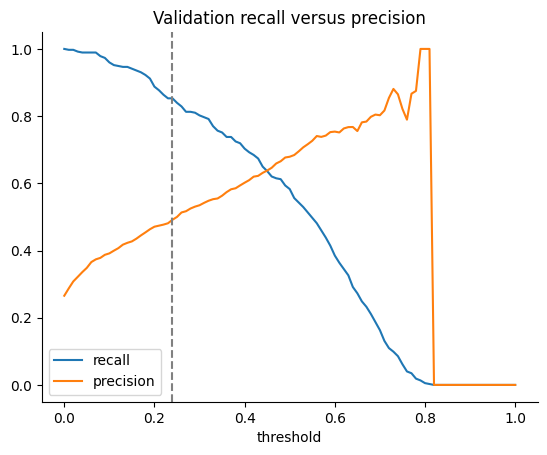

In [4]:
tradeoffs=pd.read_csv('outputs/validation_threshold_tradeoffs.csv')
display(tradeoffs[(tradeoffs.threshold>=.15)&(tradeoffs.threshold<=.35)][['threshold','recall','precision','fp','fn','diagnostic_cost_5_to_1']])
display(pd.read_csv('outputs/error_cost_sensitivity.csv'))
tradeoffs.plot(x='threshold',y=['recall','precision'],title='Validation recall versus precision')
plt.axvline(m['threshold'],ls='--',color='gray');plt.show()

## 5. Model evidence
AUC evaluates ranking; average precision summarizes the precision-recall curve; Brier and calibration inspect probability scale. The AUC interval bootstraps test rows for a fixed model, not retraining uncertainty. Permutation importance is associative; correlated predictors complicate attribution.

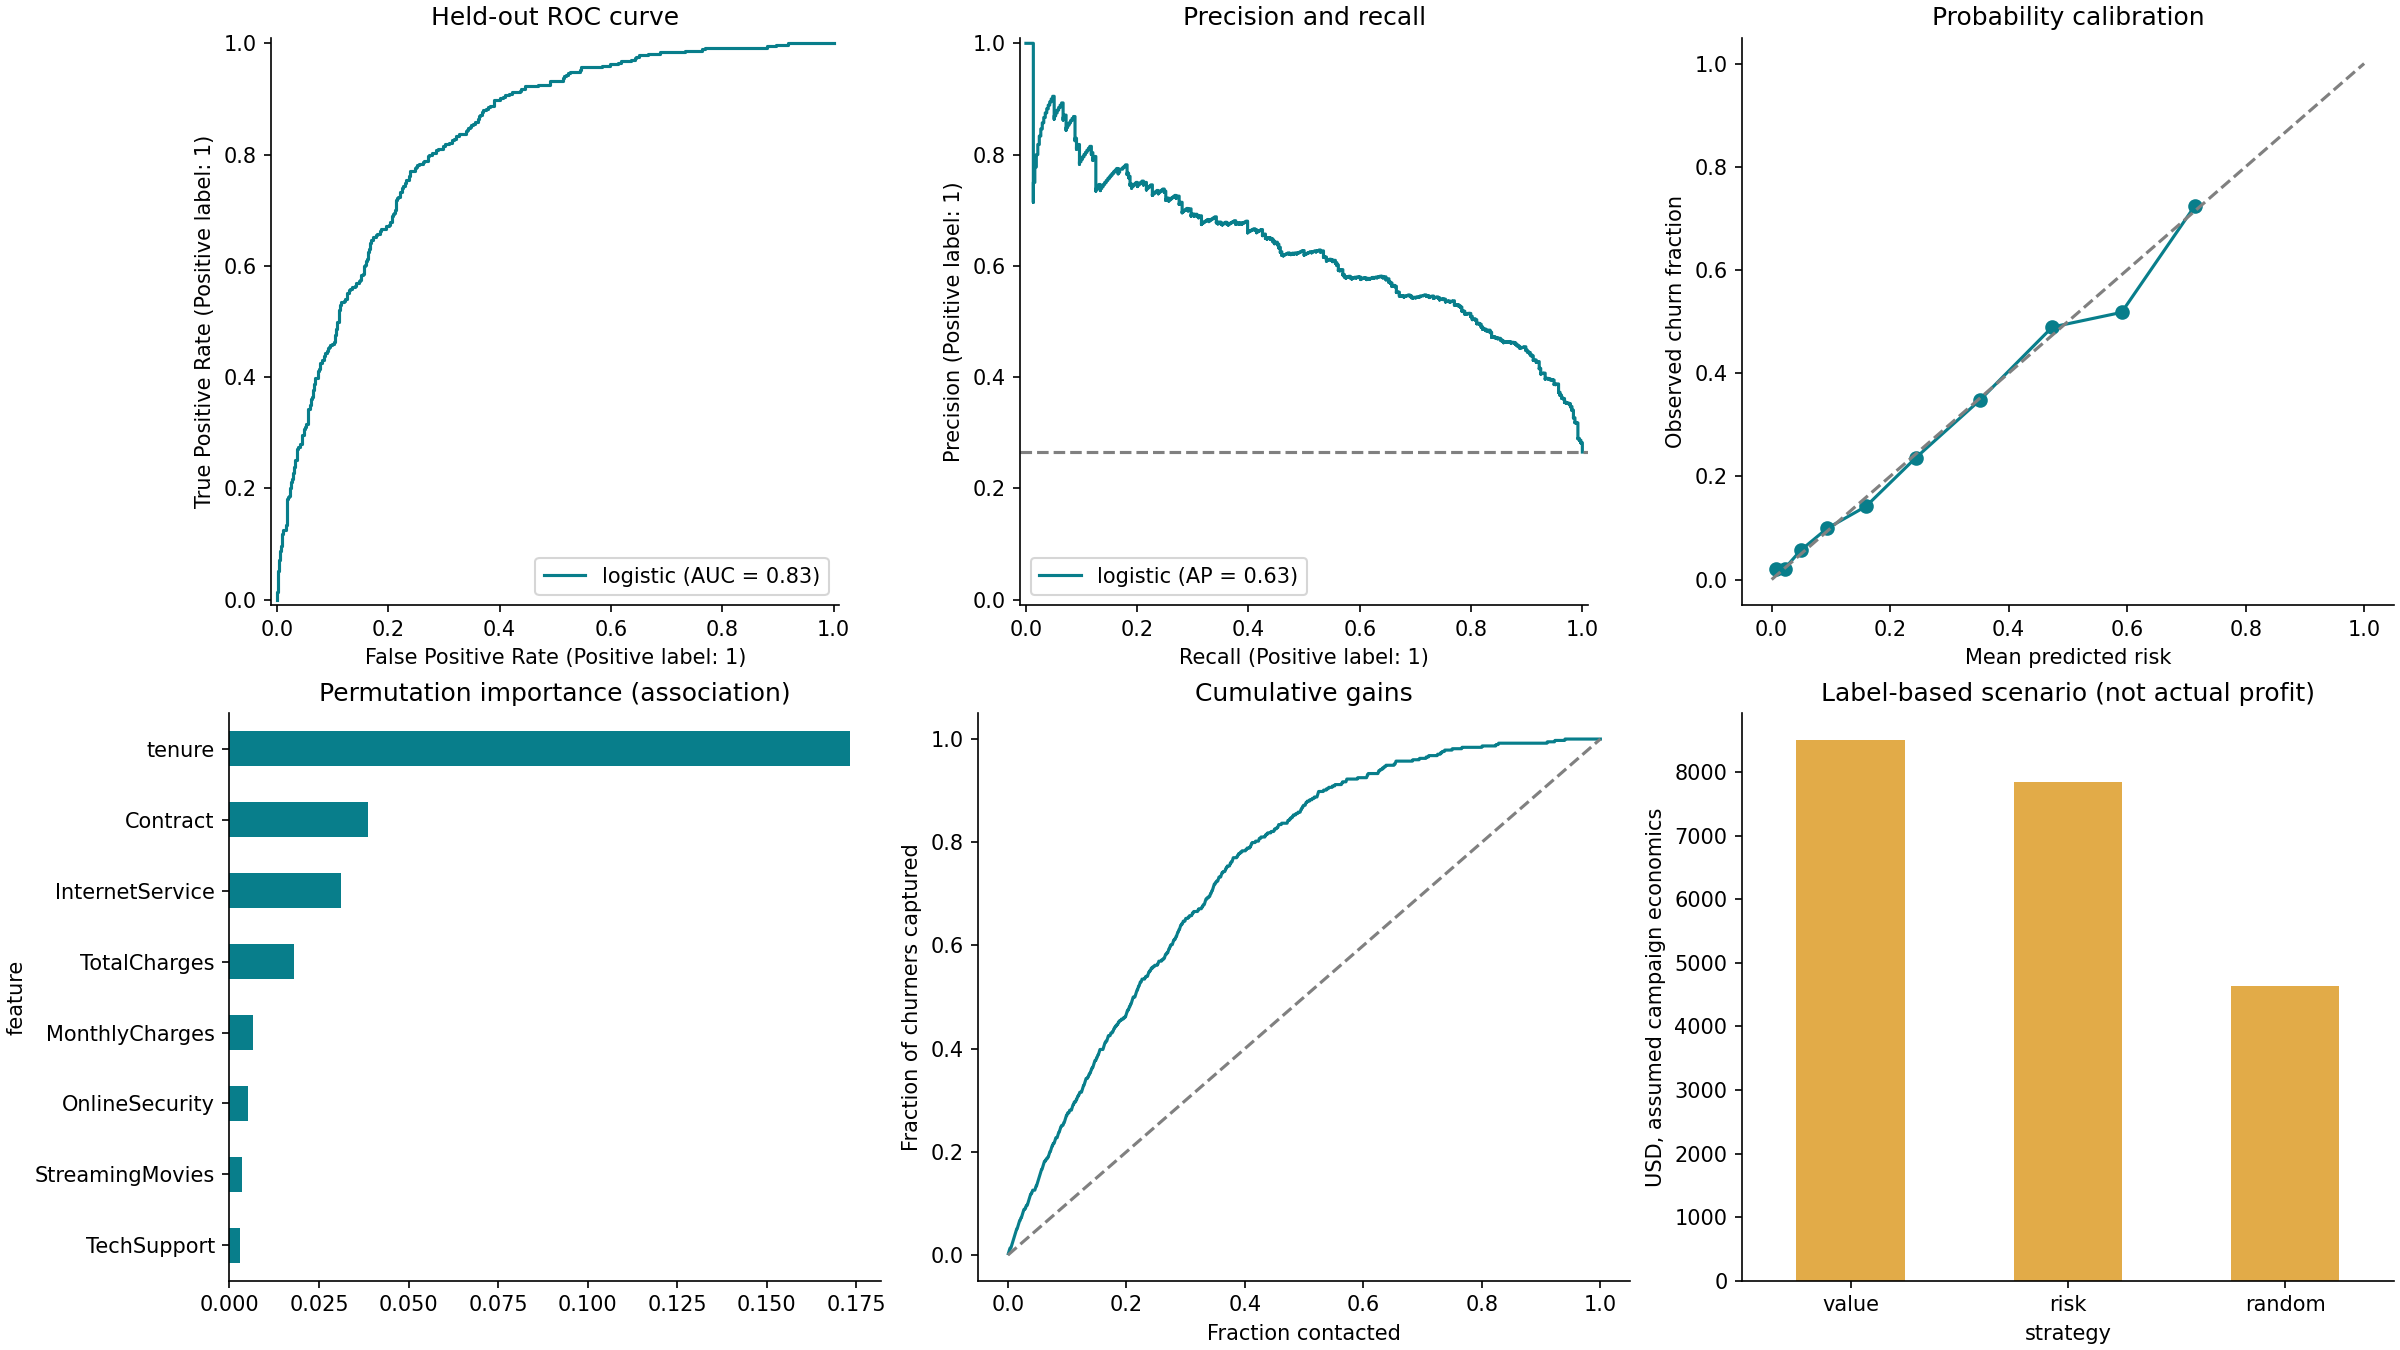

,feature,auc_drop,std
0,tenure,0.173283,0.002147
1,Contract,0.038706,0.005204
2,InternetService,0.031159,0.002686
3,TotalCharges,0.018134,0.005104
4,MonthlyCharges,0.006690,0.003282
5,OnlineSecurity,0.005096,0.002170
6,StreamingMovies,0.003554,0.002049
7,TechSupport,0.003069,0.001366
8,StreamingTV,0.002762,0.001831
9,MultipleLines,0.001649,0.001243


,attribute,group,n,observed_rate,predicted_rate,brier,recall
0,gender,Female,714,0.289916,0.280131,0.153227,0.821256
1,gender,Male,695,0.240288,0.260305,0.128997,0.838323
2,SeniorCitizen,0,1170,0.232479,0.244456,0.128670,0.805147
3,SeniorCitizen,1,239,0.426778,0.397122,0.202986,0.892157


In [5]:
display(Image(filename='outputs/evaluation.png'))
display(pd.read_csv('outputs/feature_importance.csv'))
display(pd.read_csv('outputs/subgroup_audit.csv'))

## 6. Rank customers by probability × monthly value
This is the exact walkthrough score. Use all customers, with a separate risk flag, so a high-value lower-probability account is not automatically excluded. Targets and audit attributes are stripped from the actionable list. Monthly exposure is a value score; the data do not validate a forward one-month prediction horizon.

In [6]:
evaluation=pd.read_csv('outputs/test_scores.csv')
scored=evaluation.drop(columns=['actual_churn','gender','SeniorCitizen'])
ranked=prioritize(scored,m['threshold'])
display(ranked[['priority_rank','customerID','probability','churn_flag','monthly_customer_value','expected_monthly_loss']].head(15))
print(f'Monthly revenue exposure: ${ranked.expected_monthly_loss.sum():,.2f}')
print('Flagged customers:',int(ranked.churn_flag.sum()))
# Counterexample to risk-only ranking:
example=pd.DataFrame({'customerID':['90%-risk-low-value','50%-risk-high-value'],'probability':[.9,.5],'MonthlyCharges':[20.,100.]})
display(prioritize(example,m['threshold'])[['customerID','probability','monthly_customer_value','expected_monthly_loss']])

Monthly revenue exposure: $28,314.46
Flagged customers: 640


,priority_rank,customerID,probability,churn_flag,monthly_customer_value,expected_monthly_loss
0,1,1400-MMYXY,0.777313,True,105.90,82.317492
1,2,6023-YEBUP,0.807136,True,100.95,81.480367
2,3,8884-ADFVN,0.788647,True,101.95,80.402605
3,4,2027-FECZV,0.736134,True,106.70,78.545502
4,5,0702-PGIBZ,0.769614,True,101.70,78.269743
5,6,9057-SIHCH,0.805626,True,96.60,77.823425
6,7,0295-PPHDO,0.814923,True,95.45,77.784361
7,8,7851-WZEKY,0.811624,True,95.15,77.226045
8,9,9221-OTIVJ,0.733507,True,104.85,76.908163
9,10,9300-AGZNL,0.816783,True,94.00,76.777620


,customerID,probability,monthly_customer_value,expected_monthly_loss
0,50%-risk-high-value,0.5,100.0,50.0
1,90%-risk-low-value,0.9,20.0,18.0


## 7. Set incentive limits and explain support tiers
Break-even total retention spend = p × monthly value × retained months × save rate × margin. Subtract outreach cost to obtain the remaining incentive cap. Example tier costs: outreach $5, promo $10, advisor $35. Choose only tiers strictly below break-even. Higher affordability does not prove that an expensive treatment is more effective. The highest affordable example tier is a demonstration, not an optimal causal recommendation.

In [7]:
display(ranked[['priority_rank','customerID','expected_monthly_loss','max_total_retention_spend','max_incentive_after_outreach','suggested_support_tier','planned_total_cost','expected_net_after_suggested_tier']].head(15))
print('Illustrative tier allocation:')
display(ranked.suggested_support_tier.value_counts())
print('Six retained months is a valuation assumption, not a multi-month churn forecast or lifetime value.')

Illustrative tier allocation:
Six retained months is a valuation assumption, not a multi-month churn forecast or lifetime value.


,priority_rank,customerID,expected_monthly_loss,max_total_retention_spend,max_incentive_after_outreach,suggested_support_tier,planned_total_cost,expected_net_after_suggested_tier
0,1,1400-MMYXY,82.317492,86.433366,81.433366,Dedicated advisor,40.0,46.433366
1,2,6023-YEBUP,81.480367,85.554386,80.554386,Dedicated advisor,40.0,45.554386
2,3,8884-ADFVN,80.402605,84.422736,79.422736,Dedicated advisor,40.0,44.422736
3,4,2027-FECZV,78.545502,82.472777,77.472777,Dedicated advisor,40.0,42.472777
4,5,0702-PGIBZ,78.269743,82.183230,77.183230,Dedicated advisor,40.0,42.183230
5,6,9057-SIHCH,77.823425,81.714596,76.714596,Dedicated advisor,40.0,41.714596
6,7,0295-PPHDO,77.784361,81.673579,76.673579,Dedicated advisor,40.0,41.673579
7,8,7851-WZEKY,77.226045,81.087347,76.087347,Dedicated advisor,40.0,41.087347
8,9,9221-OTIVJ,76.908163,80.753571,75.753571,Dedicated advisor,40.0,40.753571
9,10,9300-AGZNL,76.777620,80.616501,75.616501,Dedicated advisor,40.0,40.616501


suggested_support_tier
No paid outreach     512
Dedicated advisor    338
Promo code           298
Outreach only        261
Name: count, dtype: int64

## 8. Allocate capacity and estimate a campaign scenario
Separate uniform-cost scenario: 25% of otherwise churners saved, six retained months, 70% margin, $20 all-in/contact, 200-contact ceiling. Costs apply even to false positives. The uniform cost does not also charge the example tier costs. With common assumptions, exact p × monthly value order also orders expected net contribution. If interventions have different costs or save rates, this equivalence changes.

In [8]:
q=campaign(scored)
print('Selected contacts:',len(q))
print(f'Expected saved revenue: ${q.expected_saved_revenue.sum():,.2f}')
print(f'Expected net contribution: ${q.expected_net_value.sum():,.2f}')
display(pd.read_csv('outputs/policy_comparison.csv'))
sensitivity=pd.read_csv('outputs/sensitivity.csv')
display(sensitivity.pivot(index='success',columns='cost',values='expected_net'))
print('Value ranking optimizes its assumed objective by construction. Label-based scenarios still assume intervention success and are not causal validation.')

Selected contacts: 200
Expected saved revenue: $17,781.18
Expected net contribution: $8,446.82
Value ranking optimizes its assumed objective by construction. Label-based scenarios still assume intervention success and are not causal validation.


,strategy,contacts,expected_saved_revenue,expected_net_value,label_based_scenario_net
0,value,200,17781.175194,8446.822636,8496.9950
1,risk,200,17047.410969,7933.187678,7839.2750
2,random,200,13123.503753,5186.452627,4628.9525


cost,10,20,40,60
success,,,,
0.10,2978.729054,978.729054,0.000000,0.000000
0.20,7957.458109,5957.458109,1957.458109,75.799029
0.25,10446.822636,8446.822636,4446.822636,891.431762
0.30,12936.187163,10936.187163,6936.187163,2936.187163
0.40,17914.916217,15914.916217,11914.916217,7914.916217


## 9. Batch inference and handoff
Score without target or demographic columns. The interface validates schema and categories, rejects invalid charges, and uses the trusted fitted pipeline. Downloadable lists contain no actual outcomes. Only load trusted serialized models.

In [9]:
from src.score import score_frame
new=pd.read_csv('data/example_customers.csv')
assert 'Churn' not in new.columns
display(prioritize(score_frame(new),m['threshold']).head())

,priority_rank,customerID,MonthlyCharges,probability,churn_flag,monthly_customer_value,expected_monthly_loss,revenue_at_risk_scenario,expected_saved_revenue,max_total_retention_spend,max_incentive_after_outreach,suggested_support_tier,planned_incentive_cost,planned_total_cost,expected_net_after_suggested_tier
0,1,9305-CDSKC,99.65,0.788745,True,99.65,78.598474,471.590845,117.897711,82.528398,77.528398,Dedicated advisor,35.0,40.0,42.528398
1,2,7892-POOKP,104.80,0.613983,True,104.80,64.345450,386.072700,96.518175,67.562722,62.562722,Dedicated advisor,35.0,40.0,27.562722
2,3,4183-MYFRB,90.05,0.583822,True,90.05,52.573135,315.438808,78.859702,55.201791,50.201791,Dedicated advisor,35.0,40.0,15.201791
3,4,9237-HQITU,70.70,0.693502,True,70.70,49.030605,294.183627,73.545907,51.482135,46.482135,Dedicated advisor,35.0,40.0,11.482135
4,5,5129-JLPIS,105.50,0.455646,True,105.50,48.070666,288.423994,72.105999,50.474199,45.474199,Dedicated advisor,35.0,40.0,10.474199


## 10. Business recommendations and next evidence
Pilot high-exposure positive-value contacts under a fixed budget. Use the incentive cap as an upper bound and prefer the cheapest proven-effective treatment. Randomize outreach versus control within risk/value bands and measure incremental retained contribution, including actual offer redemption and contact cost. Do not claim realized savings from this benchmark.

Real deployment needs authorized time-stamped observations, a prospective label, scoring-time feature lineage, temporal validation, contact governance, calibration and subgroup monitoring. Revisit thresholds once actual FN/FP costs are known. The separate `extensions/pension` project preserves earlier member/transfer tasks with explicitly synthetic data and distinct assets-versus-fees definitions.

See `REQUIREMENTS_AUDIT.md`, `README.md`, `CASE_STUDY.md` and `GITHUB_GUIDE.md` for full rationale, mapping and recruiter presentation. Source: https://github.com/IBM/telco-customer-churn-on-icp4d .